 # Citi Bike Trip Analysis



 Анализ поведения пользователей Citi Bike:

 - спрос по времени;

 - продолжительность поездок;

 - маршруты;

 - пользовательские сегменты;

 - станции;

 - подписчики и обычные клиенты;

 - динамика поездок в течение наблюдаемого периода.



 Аналитическая логика:



 **Observation → Question → Hypothesis → Check → Result → Insight → Recommendation**

 ## Business Questions



 1. Когда спрос на Citi Bike максимален?

 2. Как меняется продолжительность поездки?

 3. Какие маршруты отличаются по длительности и расстоянию?

 4. Различается ли поведение пользовательских сегментов по времени поездки?

 5. Отличаются ли наиболее загруженные станции от остальных?

 6. Чем отличаются подписчики и обычные клиенты?

 7. Есть ли устойчивый временной паттерн в течение наблюдаемого периода?

 ## Hypotheses



 **H1.** Количество поездок различается в зависимости от дня недели и времени суток.



 **H2.** Продолжительность поездки различается в зависимости от времени суток,

 дня недели и типа пользователя.



 **H3.** Некоторые маршруты имеют существенно большую продолжительность

 и/или дистанцию, чем остальные.



 **H4.** Распределение времени начала и окончания поездок различается

 между пользовательскими сегментами.



 **H5.** Наиболее загруженные станции могут иметь другой профиль поездок

 по сравнению с остальными станциями.



 **H6.** Подписчики и обычные клиенты отличаются по количеству поездок,

 продолжительности, дистанции и времени использования.



 **H7.** Количество поездок меняется во времени, а динамика может сопровождаться

 изменениями средней продолжительности и дистанции.

 # 1. Import libraries and load data

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

DATA_PATH = Path(
    r"C:\Users\User\Documents\citidike_projects_EDA\data\processed\Citibike.csv\citibike.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (50000, 18)


,trip_id,bike_id,weekday,start_hour,start_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_time,end_station_id,end_station_name,end_station_latitude,end_station_longitude,trip_duration,subscriber,birth_year,gender
0,LnQzQk,16013,Mon,18,2013-09-09 18:18:55,523,W 38 St & 8 Ave,40.75,-73.99,2013-09-09 18:35:28,334,W 20 St & 7 Ave,40.74,-74.00,993,Subscriber,1968.00,2
1,IL9boN,15230,Thu,18,2013-09-12 18:38:53,257,Lispenard St & Broadway,40.72,-74.00,2013-09-12 18:48:34,236,St Marks Pl & 2 Ave,40.73,-73.99,581,Subscriber,1983.00,1
2,46clGB,17942,Wed,19,2013-09-18 19:44:04,479,9 Ave & W 45 St,40.76,-73.99,2013-09-18 19:50:05,513,W 56 St & 10 Ave,40.77,-73.99,361,Subscriber,1989.00,1
3,v7vdFt,19683,Sat,11,2013-09-28 11:54:37,527,E 33 St & 1 Ave,40.74,-73.97,2013-09-28 12:03:58,441,E 52 St & 2 Ave,40.76,-73.97,561,Subscriber,1988.00,2
4,VGBsb5,18024,Sat,18,2013-09-07 18:08:22,521,8 Ave & W 31 St,40.75,-73.99,2013-09-07 18:46:38,476,E 31 St & 3 Ave,40.74,-73.98,2296,Non-Subscriber,NaN,0


 # 2. Initial Data Exploration

In [7]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100
})

display(
    missing[missing["missing"] > 0]
    .sort_values("missing_%", ascending=False)
)

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nUnique values:")
display(
    df.nunique()
    .sort_values(ascending=False)
)

print("\nNumerical statistics:")
display(
    df.describe().T
)


Dataset shape:
(50000, 18)

Column names:
['trip_id', 'bike_id', 'weekday', 'start_hour', 'start_time', 'start_station_id', 'start_station_name', 'start_station_latitude', 'start_station_longitude', 'end_time', 'end_station_id', 'end_station_name', 'end_station_latitude', 'end_station_longitude', 'trip_duration', 'subscriber', 'birth_year', 'gender']

Data types:


trip_id                        str
bike_id                      int64
weekday                        str
start_hour                   int64
start_time                     str
start_station_id             int64
start_station_name             str
start_station_latitude     float64
start_station_longitude    float64
end_time                       str
end_station_id               int64
end_station_name               str
end_station_latitude       float64
end_station_longitude      float64
trip_duration                int64
subscriber                     str
birth_year                 float64
gender                       int64
dtype: object


Missing values:


,missing,missing_%
birth_year,6979,13.96



Duplicates:
0

Unique values:


trip_id                    50000
end_time                   49265
start_time                 49234
trip_duration               2544
bike_id                      996
start_station_id             330
start_station_name           330
start_station_latitude       330
start_station_longitude      330
end_station_id               330
end_station_name             330
end_station_latitude         330
end_station_longitude        330
birth_year                    76
start_hour                    24
weekday                        7
gender                         3
subscriber                     2
dtype: int64


Numerical statistics:


,count,mean,std,min,25%,50%,75%,max
bike_id,50000.00,17615.27,1675.41,14556.00,16188.00,17584.00,19014.00,20642.00
start_hour,50000.00,14.15,4.86,0.00,10.00,15.00,18.00,23.00
start_station_id,50000.00,443.32,356.56,72.00,304.00,402.00,484.00,3002.00
start_station_latitude,50000.00,40.73,0.02,40.68,40.72,40.74,40.75,40.77
start_station_longitude,50000.00,-73.99,0.01,-74.02,-74.00,-73.99,-73.98,-73.95
end_station_id,50000.00,442.54,355.76,72.00,304.00,402.00,483.00,3002.00
end_station_latitude,50000.00,40.73,0.02,40.68,40.72,40.74,40.75,40.77
end_station_longitude,50000.00,-73.99,0.01,-74.02,-74.00,-73.99,-73.98,-73.95
trip_duration,50000.00,838.98,573.66,60.00,417.00,672.00,1112.00,2697.00
birth_year,43021.00,1975.63,11.09,1899.00,1968.00,1978.00,1984.00,1997.00


 # 3. Data Cleaning



 Проверяем:

 - даты;

 - продолжительность;

 - дубликаты;

 - категориальные значения;

 - возраст;

 - согласованность времени поездки.

In [8]:
required_columns = [
    "trip_id",
    "start_time",
    "end_time",
    "trip_duration",
    "start_station_name",
    "end_station_name",
    "subscriber",
    "gender",
    "birth_year",
    "start_station_latitude",
    "start_station_longitude",
    "end_station_latitude",
    "end_station_longitude"
]

missing_required = [
    col for col in required_columns
    if col not in df.columns
]

if missing_required:
    raise ValueError(
        f"Missing required columns: {missing_required}"
    )

print("All required columns are present.")


All required columns are present.


 ## 3.1 Date validation

In [9]:
df["start_time"] = pd.to_datetime(
    df["start_time"],
    errors="coerce"
)

df["end_time"] = pd.to_datetime(
    df["end_time"],
    errors="coerce"
)

print(
    "Invalid start_time:",
    df["start_time"].isna().sum()
)

print(
    "Invalid end_time:",
    df["end_time"].isna().sum()
)


Invalid start_time: 0
Invalid end_time: 0


 ## 3.2 Duration validation

In [10]:
print(
    "Trips with duration <= 0:",
    (df["trip_duration"] <= 0).sum()
)


Trips with duration <= 0: 0


 ## 3.3 Categorical values

In [11]:
print("Subscriber types:")
display(
    df["subscriber"]
    .value_counts(dropna=False)
)

print("Gender:")
display(
    df["gender"]
    .value_counts(dropna=False)
)


Subscriber types:


subscriber
Subscriber        43021
Non-Subscriber     6979
Name: count, dtype: int64

Gender:


gender
1    32361
2    10658
0     6981
Name: count, dtype: int64

 ## 3.4 Birth year validation

In [12]:
print("Birth year statistics:")
display(
    df["birth_year"].describe()
)


Birth year statistics:


count   43021.00
mean     1975.63
std        11.09
min      1899.00
25%      1968.00
50%      1978.00
75%      1984.00
max      1997.00
Name: birth_year, dtype: float64

 ## 3.5 Duplicate validation

In [13]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)


Duplicate rows: 0


 ## 3.6 Duration consistency check



 Проверяем, соответствует ли `trip_duration` разнице между `start_time`

 и `end_time`.

In [14]:
df["calculated_duration_sec"] = (
    df["end_time"] - df["start_time"]
).dt.total_seconds()

duration_difference = (
    df["calculated_duration_sec"]
    - df["trip_duration"]
).abs()

print(
    "Rows with duration difference > 1 sec:",
    (duration_difference > 1).sum()
)


Rows with duration difference > 1 sec: 1019


 ## 3.7 Remove technically invalid rows

In [15]:
df = df.dropna(
    subset=[
        "start_time",
        "end_time",
        "trip_duration"
    ]
)

df = df[
    df["trip_duration"] > 0
]

df = df.drop_duplicates()

print(
    "Dataset shape after basic cleaning:",
    df.shape
)


Dataset shape after basic cleaning: (50000, 19)


Dataset successfully saved!
Rows: 50,000
Columns: 36
File: data/raw/citi_bike_cleaned.csv


 # 4. Feature Engineering

 ## 4.1 Date and time features

In [16]:
df["date"] = df["start_time"].dt.date

df["month"] = (
    df["start_time"]
    .dt.to_period("M")
    .astype(str)
)

df["week"] = (
    df["start_time"]
    .dt.to_period("W")
    .astype(str)
)

df["hour"] = df["start_time"].dt.hour

df["start_hour"] = (
    df["start_time"].dt.hour
)

df["end_hour"] = (
    df["end_time"].dt.hour
)

df["day_of_week"] = (
    df["start_time"].dt.day_name()
)

df["day_of_week_num"] = (
    df["start_time"].dt.dayofweek
)


 ## 4.2 Trip duration



 `trip_duration` хранится в секундах.



 Поэтому:



 **duration_min = trip_duration / 60**

In [17]:
df["duration_min"] = (
    df["trip_duration"] / 60
)

# Проверка
display(
    df[
        [
            "trip_duration",
            "duration_min"
        ]
    ].head()
)


,trip_duration,duration_min
0,993,16.55
1,581,9.68
2,361,6.02
3,561,9.35
4,2296,38.27


 ## 4.3 Time segments

In [18]:
def get_time_segment(hour):

    if 5 <= hour < 9:
        return "Morning"

    elif 9 <= hour < 12:
        return "Late morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"


df["time_segment"] = (
    df["start_hour"]
    .apply(get_time_segment)
)

df["time_segment_end"] = (
    df["end_hour"]
    .apply(get_time_segment)
)


 ## 4.4 Duration segments

In [19]:
duration_bins = [
    0,
    10,
    20,
    30,
    60,
    np.inf
]

duration_labels = [
    "Very short",
    "Short",
    "Medium",
    "Long",
    "Very long"
]

df["duration_segment"] = pd.cut(
    df["duration_min"],
    bins=duration_bins,
    labels=duration_labels,
    right=False
)


 ## 4.5 Distance calculation



 Расстояние между стартовой и конечной станциями рассчитывается

 по формуле Haversine.

In [20]:
lat1 = np.radians(
    df["start_station_latitude"]
)

lat2 = np.radians(
    df["end_station_latitude"]
)

lon1 = np.radians(
    df["start_station_longitude"]
)

lon2 = np.radians(
    df["end_station_longitude"]
)

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    +
    np.cos(lat1)
    * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

a = np.clip(a, 0, 1)

c = 2 * np.arcsin(
    np.sqrt(a)
)

df["distance_km"] = (
    6371 * c
)


 ## 4.6 Distance segments

In [21]:
distance_bins = [
    0,
    1,
    2,
    5,
    10,
    np.inf
]

distance_labels = [
    "Very short",
    "Short",
    "Medium",
    "Long",
    "Very long"
]

df["distance_segment"] = pd.cut(
    df["distance_km"],
    bins=distance_bins,
    labels=distance_labels,
    right=False
)


 ## 4.7 Age

In [22]:
df["age"] = (
    df["start_time"].dt.year
    - df["birth_year"]
)

# Remove obviously invalid ages
df.loc[
    (df["age"] < 0)
    |
    (df["age"] > 120),
    "age"
] = np.nan

df["age_segment"] = pd.cut(
    df["age"],
    bins=[
        0,
        20,
        35,
        50,
        65,
        120
    ],
    labels=[
        "0-20",
        "21-35",
        "36-50",
        "51-65",
        "65+"
    ],
    right=False
)


 ## 4.8 Final feature check

In [23]:
new_features = [
    "date",
    "month",
    "week",
    "hour",
    "day_of_week",
    "time_segment",
    "duration_min",
    "duration_segment",
    "distance_km",
    "distance_segment",
    "age",
    "age_segment"
]

display(
    df[new_features].head()
)


,date,month,week,hour,day_of_week,time_segment,duration_min,duration_segment,distance_km,distance_segment,age,age_segment
0,2013-09-09,2013-09,2013-09-09/2013-09-15,18,Monday,Evening,16.55,Short,1.45,Short,45.00,36-50
1,2013-09-12,2013-09,2013-09-09/2013-09-15,18,Thursday,Evening,9.68,Very short,1.64,Short,30.00,21-35
2,2013-09-18,2013-09,2013-09-16/2013-09-22,19,Wednesday,Evening,6.02,Very short,0.92,Very short,24.00,21-35
3,2013-09-28,2013-09,2013-09-23/2013-09-29,11,Saturday,Late morning,9.35,Very short,1.54,Short,25.00,21-35
4,2013-09-07,2013-09,2013-09-02/2013-09-08,18,Saturday,Evening,38.27,Long,1.47,Short,NaN,NaN


 # 5. Overall Dataset Summary

In [24]:
summary = pd.DataFrame({
    "Metric": [
        "Total trips",
        "Unique trips",
        "Mean duration, min",
        "Median duration, min",
        "Mean distance, km",
        "Median distance, km"
    ],

    "Value": [
        len(df),
        df["trip_id"].nunique(),
        df["duration_min"].mean(),
        df["duration_min"].median(),
        df["distance_km"].mean(),
        df["distance_km"].median()
    ]
})

display(
    summary.round(2)
)


,Metric,Value
0,Total trips,50000.00
1,Unique trips,50000.00
2,"Mean duration, min",13.98
3,"Median duration, min",11.20
4,"Mean distance, km",1.86
5,"Median distance, km",1.49


In [63]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df[df["duration_min"].between(0, 120)],
    x="duration_min",
    bins=50,
    color="steelblue"
)
plt.title("Trip Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

AttributeError: module 'matplotlib.pyplot' has no attribute 'figsize'

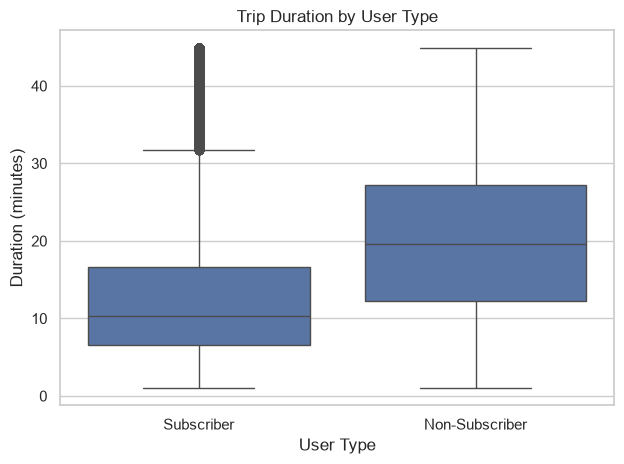

In [76]:
sns.boxplot(
    data=df[df["duration_min"].between(0, 120)],
    x="subscriber",
    y="duration_min"
)
plt.title("Trip Duration by User Type")
plt.xlabel("User Type")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

 # H1. Demand by Time



 **Question:** Когда спрос на Citi Bike максимален?



 **Hypothesis:** количество поездок различается в зависимости от дня недели

 и времени суток.

In [25]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_trips = (
    df.groupby("day_of_week")["trip_id"]
    .count()
    .reindex(weekday_order)
)

display(
    weekly_trips.to_frame("trips")
)


,trips
day_of_week,
Monday,7715
Tuesday,7065
Wednesday,7228
Thursday,6857
Friday,7309
Saturday,6507
Sunday,7319


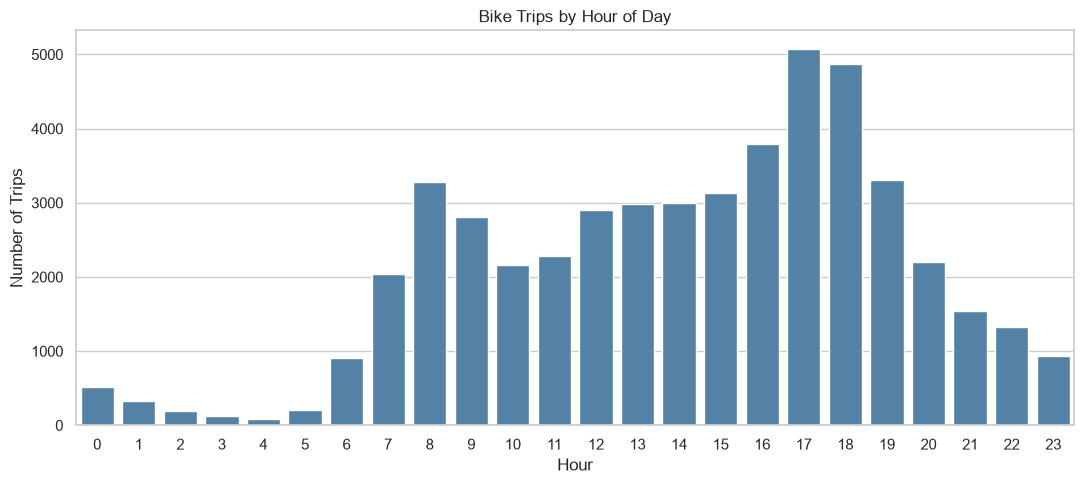

In [69]:
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="hour", color="steelblue")

plt.title("Bike Trips by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

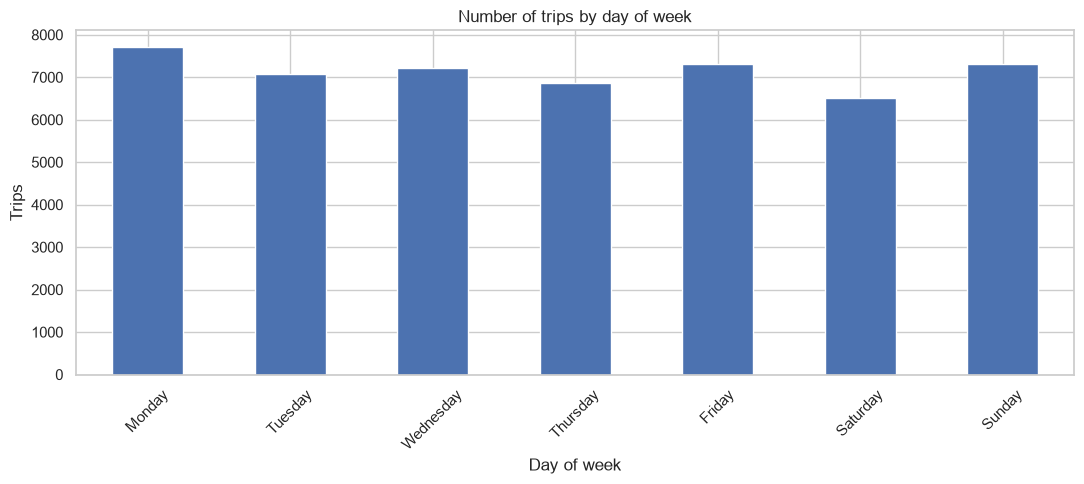

In [26]:
plt.figure(figsize=(11, 5))

weekly_trips.plot(
    kind="bar"
)

plt.title(
    "Number of trips by day of week"
)

plt.xlabel(
    "Day of week"
)

plt.ylabel(
    "Trips"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


In [27]:
time_order = [
    "Morning",
    "Late morning",
    "Afternoon",
    "Evening",
    "Night"
]

time_trips = (
    df.groupby("time_segment")["trip_id"]
    .count()
    .reindex(time_order)
)

display(
    time_trips.to_frame("trips")
)


,trips
time_segment,
Morning,6446
Late morning,7254
Afternoon,15802
Evening,15452
Night,5046


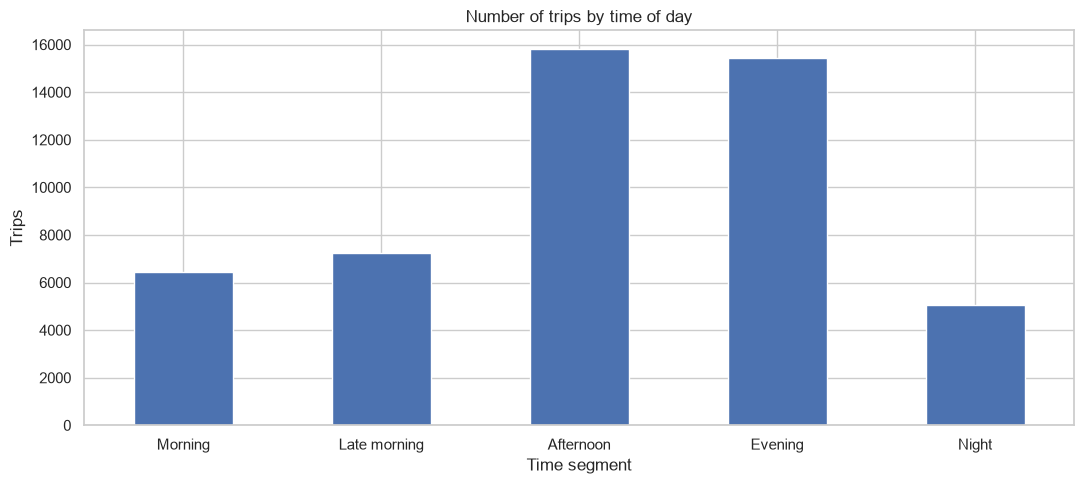

In [28]:
plt.figure(figsize=(11, 5))

time_trips.plot(
    kind="bar"
)

plt.title(
    "Number of trips by time of day"
)

plt.xlabel(
    "Time segment"
)

plt.ylabel(
    "Trips"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()


In [29]:
day_time_trips = (
    df.groupby(
        [
            "day_of_week",
            "time_segment"
        ]
    )["trip_id"]
    .count()
    .unstack(
        fill_value=0
    )
    .reindex(weekday_order)
)

display(
    day_time_trips
)


time_segment,Afternoon,Evening,Late morning,Morning,Night
day_of_week,,,,,
Monday,2127,2657,1120,1091,720
Tuesday,1812,2407,927,1260,659
Wednesday,1867,2378,1065,1237,681
Thursday,1855,2133,969,1216,684
Friday,2175,2198,1085,1136,715
Saturday,2768,1691,1006,274,768
Sunday,3198,1988,1082,232,819


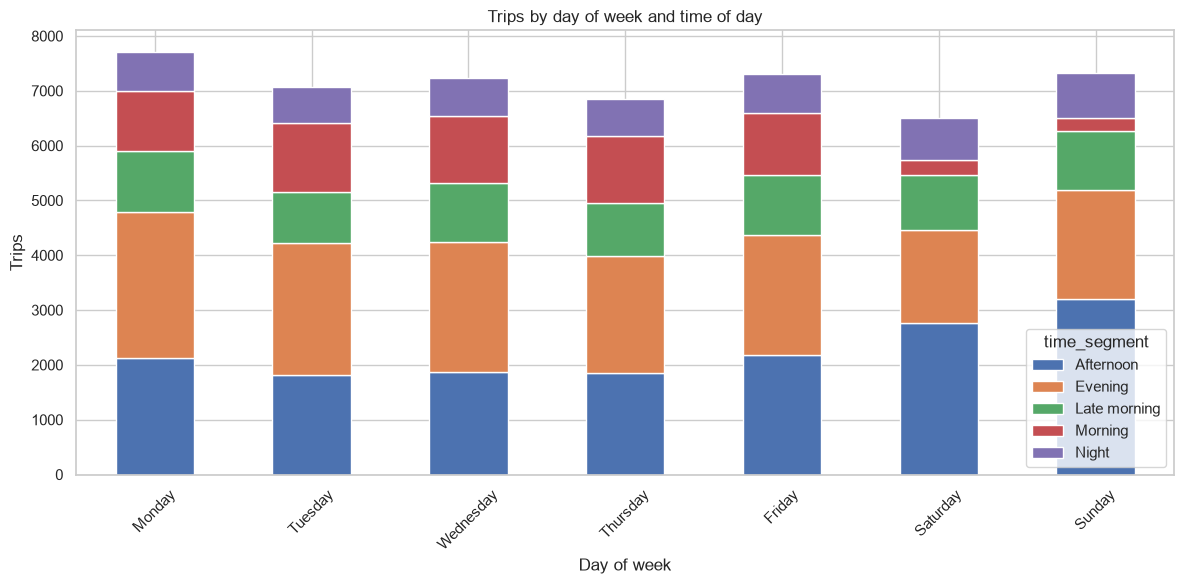

In [30]:
plt.figure(figsize=(12, 6))

day_time_trips.plot(
    kind="bar",
    stacked=True,
    ax=plt.gca()
)

plt.title(
    "Trips by day of week and time of day"
)

plt.xlabel(
    "Day of week"
)

plt.ylabel(
    "Trips"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


In [31]:
time_share = (
    time_trips
    / time_trips.sum()
    * 100
)

display(
    time_share
    .sort_values(
        ascending=False
    )
    .to_frame("share_%")
    .round(2)
)


,share_%
time_segment,
Afternoon,31.60
Evening,30.90
Late morning,14.51
Morning,12.89
Night,10.09


 ## H1 — Result



 Основной вывод формируется по абсолютному количеству поездок и доле каждого

 временного сегмента.



 Не делаем предположение о причинах высокой активности без дополнительной проверки.

 # H2. Trip Duration



 **Question:** Как меняется продолжительность поездки?



 **Hypothesis:** продолжительность отличается по времени суток,

 дню недели и типу пользователя.

In [32]:
duration_by_time = (
    df.groupby("time_segment")["duration_min"]
    .agg(
        trips="count",
        mean="mean",
        median="median"
    )
    .reindex(time_order)
)

display(
    duration_by_time.round(2)
)


,trips,mean,median
time_segment,,,
Morning,6446,12.42,10.06
Late morning,7254,13.66,10.75
Afternoon,15802,14.74,11.76
Evening,15452,14.26,11.55
Night,5046,13.23,10.66


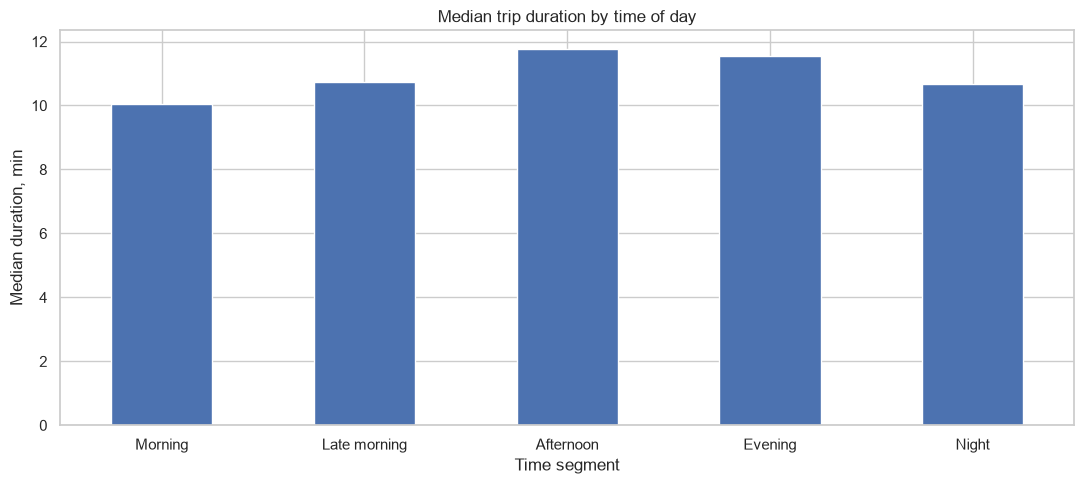

In [33]:
plt.figure(figsize=(11, 5))

duration_by_time["median"].plot(
    kind="bar"
)

plt.title(
    "Median trip duration by time of day"
)

plt.xlabel(
    "Time segment"
)

plt.ylabel(
    "Median duration, min"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()


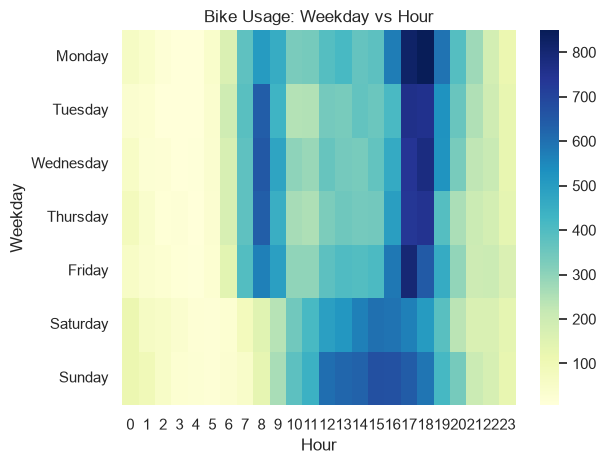

In [71]:
heatmap_data = df.pivot_table(
    index="day_of_week",
    columns="hour",
    values="duration_min",
    aggfunc="count"
).reindex(weekday_order)

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu"
)
plt.title("Bike Usage: Weekday vs Hour")
plt.xlabel("Hour")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

In [34]:
duration_by_weekday = (
    df.groupby("day_of_week")["duration_min"]
    .agg(
        trips="count",
        mean="mean",
        median="median"
    )
    .reindex(weekday_order)
)

display(
    duration_by_weekday.round(2)
)


,trips,mean,median
day_of_week,,,
Monday,7715,13.65,10.85
Tuesday,7065,13.19,10.53
Wednesday,7228,13.42,10.78
Thursday,6857,13.12,10.72
Friday,7309,13.47,10.80
Saturday,6507,15.52,12.57
Sunday,7319,15.60,12.78


In [35]:
subscriber_duration = (
    df.groupby("subscriber")["duration_min"]
    .agg(
        trips="count",
        mean="mean",
        median="median"
    )
    .sort_values(
        "trips",
        ascending=False
    )
)

display(
    subscriber_duration.round(2)
)


,trips,mean,median
subscriber,,,
Subscriber,43021,12.84,10.35
Non-Subscriber,6979,21.01,19.62


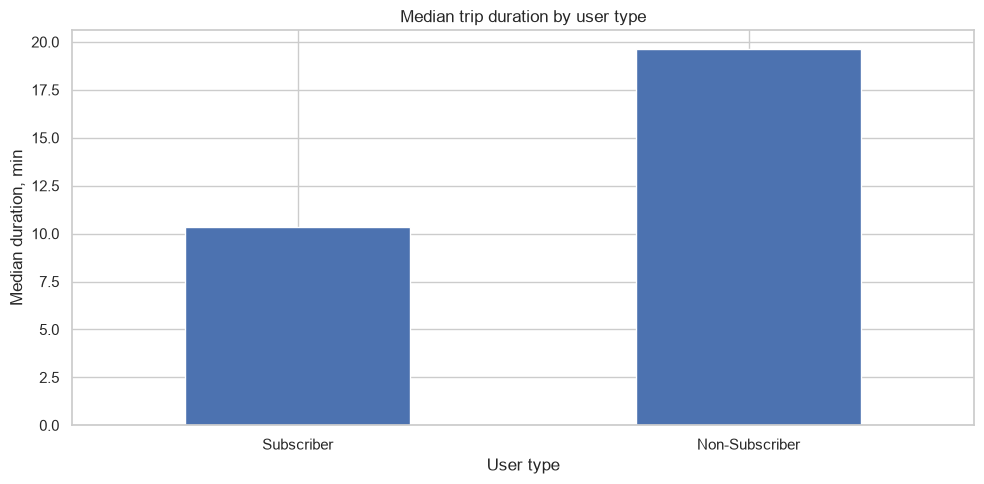

In [36]:
plt.figure(figsize=(10, 5))

subscriber_duration["median"].plot(
    kind="bar"
)

plt.title(
    "Median trip duration by user type"
)

plt.xlabel(
    "User type"
)

plt.ylabel(
    "Median duration, min"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()


 ## H2 — Result



 Среднее и медиана сравниваются одновременно, поскольку распределение

 продолжительности может содержать длинный хвост.



 Финальный инсайт должен содержать конкретные значения и разницу между группами.

 # H3. Route Characteristics



 **Question:** Какие маршруты отличаются по длительности и расстоянию?



 **Problem with previous approach:** сумма длительности зависит от количества

 поездок. Поэтому популярный маршрут автоматически получает большую сумму.



 Для сравнения маршрутов используем:

 - количество поездок;

 - среднюю длительность;

 - медианную длительность;

 - среднюю дистанцию;

 - медианную дистанцию.

In [37]:
route_stats = (
    df.groupby(
        [
            "start_station_name",
            "end_station_name"
        ]
    )
    .agg(
        trips=("trip_id", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_distance=("distance_km", "mean"),
        median_distance=("distance_km", "median")
    )
    .reset_index()
)

print(
    "Total routes:",
    len(route_stats)
)


Total routes: 27667


 ## Filter routes with sufficient observations

In [38]:
route_stats_10 = route_stats[
    route_stats["trips"] >= 10
].copy()

print(
    "Routes with at least 10 trips:",
    len(route_stats_10)
)


Routes with at least 10 trips: 123


In [39]:
print(
    "Top routes by median duration:"
)

display(
    route_stats_10
    .sort_values(
        "median_duration",
        ascending=False
    )
    .head(10)
)


Top routes by median duration:


,start_station_name,end_station_name,trips,avg_duration,median_duration,avg_distance,median_distance
14028,Grand Army Plaza & Central Park S,Central Park S & 6 Ave,15,34.46,39.83,0.28,0.28
5270,Broadway & W 58 St,Broadway & W 58 St,21,31.37,38.50,0.00,0.00
5887,Central Park S & 6 Ave,Central Park S & 6 Ave,77,32.70,34.85,0.00,0.00
5400,Broadway & W 60 St,Broadway & W 60 St,30,30.42,33.88,0.00,0.00
5886,Central Park S & 6 Ave,Broadway & W 60 St,18,27.95,32.07,0.59,0.59
27387,West Thames St,West Thames St,12,31.23,31.33,0.00,0.00
20809,Vesey Pl & River Terrace,Vesey Pl & River Terrace,13,27.88,30.67,0.00,0.00
5976,Centre St & Chambers St,Centre St & Chambers St,14,29.91,30.60,0.00,0.00
2807,Atlantic Ave & Furman St,Atlantic Ave & Furman St,12,28.16,29.07,0.00,0.00
27139,West St & Chambers St,12 Ave & W 40 St,15,31.01,29.02,4.90,4.90


In [40]:
print(
    "Top routes by median distance:"
)

display(
    route_stats_10
    .sort_values(
        "median_distance",
        ascending=False
    )
    .head(10)
)


Top routes by median distance:


,start_station_name,end_station_name,trips,avg_duration,median_duration,avg_distance,median_distance
740,12 Ave & W 40 St,West St & Chambers St,14,22.39,20.93,4.90,4.90
27139,West St & Chambers St,12 Ave & W 40 St,15,31.01,29.02,4.90,4.90
23664,W 34 St & 11 Ave,West St & Chambers St,10,23.21,21.43,4.37,4.37
22031,W 20 St & 11 Ave,West St & Chambers St,15,17.73,17.40,3.28,3.28
27251,West St & Chambers St,W 20 St & 11 Ave,14,16.74,15.08,3.28,3.28
21344,W 14 St & The High Line,West St & Chambers St,16,19.38,17.35,2.75,2.75
27246,West St & Chambers St,W 14 St & The High Line,10,18.18,16.21,2.75,2.75
27280,West St & Chambers St,Washington St & Gansevoort St,12,18.12,14.29,2.46,2.46
26982,Washington St & Gansevoort St,West St & Chambers St,10,15.33,11.80,2.46,2.46
5521,Cadman Plaza E & Tillary St,Centre St & Chambers St,12,22.14,23.02,2.23,2.23


In [41]:
print(
    "Top routes by trip volume:"
)

display(
    route_stats_10
    .sort_values(
        "trips",
        ascending=False
    )
    .head(10)
)


Top routes by trip volume:


,start_station_name,end_station_name,trips,avg_duration,median_duration,avg_distance,median_distance
5887,Central Park S & 6 Ave,Central Park S & 6 Ave,77,32.70,34.85,0.00,0.00
14063,Grand Army Plaza & Central Park S,Grand Army Plaza & Central Park S,31,29.34,28.65,0.00,0.00
5400,Broadway & W 60 St,Broadway & W 60 St,30,30.42,33.88,0.00,0.00
14027,Grand Army Plaza & Central Park S,Broadway & W 60 St,25,16.41,6.92,0.87,0.87
26827,Washington Square E,University Pl & E 14 St,23,4.39,3.55,0.58,0.58
646,12 Ave & W 40 St,12 Ave & W 40 St,21,23.18,25.22,0.00,0.00
5270,Broadway & W 58 St,Broadway & W 58 St,21,31.37,38.50,0.00,0.00
17506,Metropolitan Ave & Bedford Ave,Metropolitan Ave & Bedford Ave,20,27.17,28.62,0.00,0.00
5444,Broadway & W 60 St,Grand Army Plaza & Central Park S,19,23.00,15.47,0.87,0.87
21578,W 17 St & 8 Ave,8 Ave & W 31 St,18,7.49,6.16,1.12,1.12


In [42]:
print(
    "Overall duration and distance:"
)

display(
    df[
        [
            "duration_min",
            "distance_km"
        ]
    ]
    .agg(
        [
            "mean",
            "median",
            "max"
        ]
    )
    .round(2)
)


Overall duration and distance:


,duration_min,distance_km
mean,13.98,1.86
median,11.20,1.49
max,44.95,10.12


 ## H3 — Result



 Для определения длинных маршрутов используем медианную длительность и дистанцию,

 а также минимальный порог в 10 поездок.



 Это предотвращает ситуацию, когда единичная необычная поездка становится

 «самым длинным маршрутом».

 # H4. User Segment Time Patterns



 **Question:** Различается ли время начала и окончания поездок между сегментами?



 Сегменты:

 - subscriber;

 - age;

 - gender.

In [43]:
def time_distribution(
    group_column,
    time_column
):
    return (
        df.pivot_table(
            index=group_column,
            columns=time_column,
            values="trip_id",
            aggfunc="count",
            fill_value=0
        )
    )


In [44]:
print(
    "Start time by subscriber:"
)

display(
    time_distribution(
        "subscriber",
        "time_segment"
    )
)

print(
    "End time by subscriber:"
)

display(
    time_distribution(
        "subscriber",
        "time_segment_end"
    )
)


Start time by subscriber:


time_segment,Afternoon,Evening,Late morning,Morning,Night
subscriber,,,,,
Non-Subscriber,3151,1904,983,248,693
Subscriber,12651,13548,6271,6198,4353


End time by subscriber:


time_segment_end,Afternoon,Evening,Late morning,Morning,Night
subscriber,,,,,
Non-Subscriber,3026,2140,855,183,775
Subscriber,12310,13972,6512,5530,4697


In [45]:
print(
    "Start time by age group:"
)

display(
    time_distribution(
        "age_segment",
        "time_segment"
    )
)

print(
    "End time by age group:"
)

display(
    time_distribution(
        "age_segment",
        "time_segment_end"
    )
)


Start time by age group:


time_segment,Afternoon,Evening,Late morning,Morning,Night
age_segment,,,,,
0-20,112,90,48,28,46
21-35,5624,6838,2722,2660,2561
36-50,4708,4727,2387,2374,1320
51-65,1976,1744,1002,1064,391
65+,231,149,112,72,35


End time by age group:


time_segment_end,Afternoon,Evening,Late morning,Morning,Night
age_segment,,,,,
0-20,106,94,50,25,49
21-35,5492,6978,2817,2362,2756
36-50,4579,4900,2502,2115,1420
51-65,1912,1836,1029,964,436
65+,221,164,114,64,36


In [46]:
print(
    "Start time by gender:"
)

display(
    time_distribution(
        "gender",
        "time_segment"
    )
)

print(
    "End time by gender:"
)

display(
    time_distribution(
        "gender",
        "time_segment_end"
    )
)


Start time by gender:


time_segment,Afternoon,Evening,Late morning,Morning,Night
gender,,,,,
0,3153,1904,983,248,693
1,9441,10108,4625,4764,3423
2,3208,3440,1646,1434,930


End time by gender:


time_segment_end,Afternoon,Evening,Late morning,Morning,Night
gender,,,,,
0,3028,2140,855,183,775
1,9214,10406,4760,4310,3671
2,3094,3566,1752,1220,1026


 ## Normalized distributions



 Абсолютные значения могут вводить в заблуждение, если размеры групп различаются.

 Поэтому дополнительно считаем доли внутри каждого сегмента.

In [47]:
def normalized_distribution(
    group_column,
    time_column
):

    table = time_distribution(
        group_column,
        time_column
    )

    return (
        table
        .div(
            table.sum(axis=1),
            axis=0
        )
        * 100
    )


In [48]:
print(
    "Start time distribution by subscriber:"
)

display(
    normalized_distribution(
        "subscriber",
        "time_segment"
    ).round(2)
)


Start time distribution by subscriber:


time_segment,Afternoon,Evening,Late morning,Morning,Night
subscriber,,,,,
Non-Subscriber,45.15,27.28,14.09,3.55,9.93
Subscriber,29.41,31.49,14.58,14.41,10.12


In [49]:
print(
    "Start time distribution by age group:"
)

display(
    normalized_distribution(
        "age_segment",
        "time_segment"
    ).round(2)
)


Start time distribution by age group:


time_segment,Afternoon,Evening,Late morning,Morning,Night
age_segment,,,,,
0-20,34.57,27.78,14.81,8.64,14.20
21-35,27.56,33.51,13.34,13.04,12.55
36-50,30.34,30.47,15.38,15.30,8.51
51-65,31.99,28.23,16.22,17.23,6.33
65+,38.56,24.87,18.70,12.02,5.84


In [50]:
print(
    "Start time distribution by gender:"
)

display(
    normalized_distribution(
        "gender",
        "time_segment"
    ).round(2)
)


Start time distribution by gender:


time_segment,Afternoon,Evening,Late morning,Morning,Night
gender,,,,,
0,45.17,27.27,14.08,3.55,9.93
1,29.17,31.24,14.29,14.72,10.58
2,30.10,32.28,15.44,13.45,8.73


 ## H4 — Result



 Сегменты сравниваются по долям внутри группы.



 Это позволяет определить, действительно ли поведение различается,

 а не просто отражает разный размер групп.

 # H5. Top Stations



 **Question:** Отличаются ли наиболее загруженные станции от остальных?



 Сначала определяем Top-10 станций по общему количеству появлений

 в качестве стартовой или конечной станции.

In [51]:
station_counts = pd.concat(
    [
        df["start_station_name"],
        df["end_station_name"]
    ]
).value_counts()

top_10_stations = (
    station_counts
    .head(10)
    .index
)

display(
    station_counts
    .head(10)
    .to_frame("trips")
)


,trips
E 17 St & Broadway,1068
W 20 St & 11 Ave,1061
Lafayette St & E 8 St,935
West St & Chambers St,935
Pershing Square N,851
8 Ave & W 31 St,849
University Pl & E 14 St,795
W 4 St & 7 Ave S,770
W 21 St & 6 Ave,758
Broadway & E 14 St,756


In [52]:
df["start_station_segment"] = np.where(
    df["start_station_name"]
    .isin(top_10_stations),
    "Top 10",
    "Other"
)

df["end_station_segment"] = np.where(
    df["end_station_name"]
    .isin(top_10_stations),
    "Top 10",
    "Other"
)


In [53]:
start_station_stats = (
    df.groupby(
        "start_station_segment"
    )
    .agg(
        trips=("trip_id", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_distance=("distance_km", "mean"),
        median_distance=("distance_km", "median")
    )
)

end_station_stats = (
    df.groupby(
        "end_station_segment"
    )
    .agg(
        trips=("trip_id", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_distance=("distance_km", "mean"),
        median_distance=("distance_km", "median")
    )
)

print(
    "Start station comparison:"
)

display(
    start_station_stats.round(2)
)

print(
    "End station comparison:"
)

display(
    end_station_stats.round(2)
)


Start station comparison:


,trips,avg_duration,median_duration,avg_distance,median_distance
start_station_segment,,,,,
Other,45543,14.05,11.25,1.86,1.49
Top 10,4457,13.26,10.65,1.84,1.47


End station comparison:


,trips,avg_duration,median_duration,avg_distance,median_distance
end_station_segment,,,,,
Other,45679,14.06,11.28,1.86,1.49
Top 10,4321,13.13,10.43,1.85,1.47


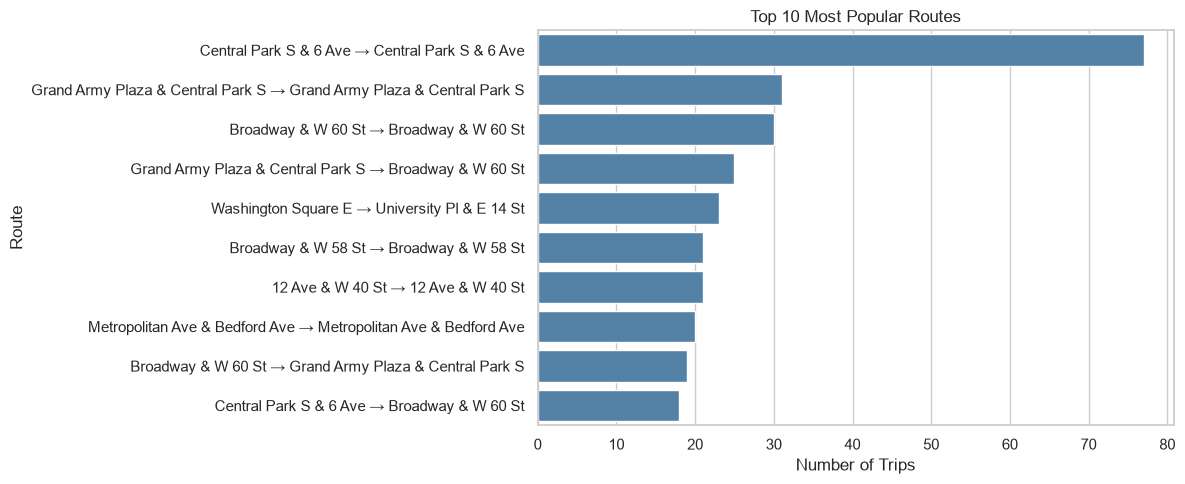

In [81]:
plt.figure(figsize=(12, 5))
top_routes = (
    df.groupby(
        ["start_station_name", "end_station_name"]
    )
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="trips")
)

top_routes["route"] = (
    top_routes["start_station_name"]
    + " → "
    + top_routes["end_station_name"]
)

sns.barplot(
    data=top_routes,
    x="trips",
    y="route",
    color="steelblue"
)
plt.title("Top 10 Most Popular Routes")
plt.xlabel("Number of Trips")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

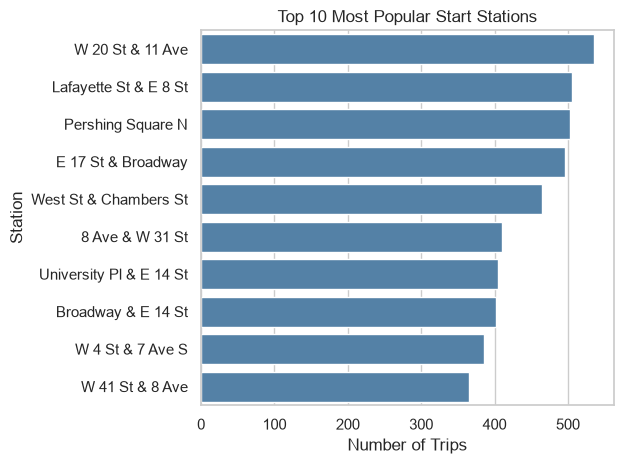

In [82]:
top_stations = df["start_station_name"].value_counts().head(10)

sns.barplot(
    x=top_stations.values,
    y=top_stations.index,
    color="steelblue"
)
plt.title("Top 10 Most Popular Start Stations")
plt.xlabel("Number of Trips")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

 ## User composition

In [54]:
print(
    "Gender composition:"
)

display(
    pd.crosstab(
        df["gender"],
        df["start_station_segment"],
        normalize="columns"
    )
    .mul(100)
    .round(2)
)


Gender composition:


start_station_segment,Other,Top 10
gender,,
0,14.09,12.65
1,64.66,65.34
2,21.25,22.01


In [55]:
print(
    "Age composition:"
)

display(
    pd.crosstab(
        df["age_segment"],
        df["start_station_segment"],
        normalize="columns"
    )
    .mul(100)
    .round(2)
)


Age composition:


start_station_segment,Other,Top 10
age_segment,,
0-20,0.75,0.80
21-35,47.61,45.58
36-50,36.00,36.70
51-65,14.22,15.79
65+,1.42,1.13


 ## H5 — Result



 Сравниваем Top-10 и остальные станции не по самому объёму,

 поскольку Top-10 определены именно по объёму, а по:



 - типичной продолжительности;

 - типичной дистанции;

 - структуре пользователей.



 Это позволяет определить, отличается ли профиль поездок на наиболее

 загруженных станциях.

 # H6. Subscribers vs Customers



 **Question:** Чем отличаются подписчики и обычные клиенты?



 Сравниваем:

 - количество поездок;

 - долю поездок;

 - среднюю и медианную длительность;

 - среднюю и медианную дистанцию;

 - среднее время начала;

 - распределение времени суток.

In [56]:
subscriber_stats = (
    df.groupby("subscriber")
    .agg(
        trips=("trip_id", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_distance=("distance_km", "mean"),
        median_distance=("distance_km", "median"),
        avg_start_hour=("start_hour", "mean")
    )
)

subscriber_stats["trip_share_%"] = (
    subscriber_stats["trips"]
    / subscriber_stats["trips"].sum()
    * 100
)

display(
    subscriber_stats.round(2)
)


,trips,avg_duration,median_duration,avg_distance,median_distance,avg_start_hour,trip_share_%
subscriber,,,,,,,
Non-Subscriber,6979,21.01,19.62,1.92,1.66,14.52,13.96
Subscriber,43021,12.84,10.35,1.85,1.47,14.08,86.04


In [57]:
subscriber_time = pd.crosstab(
    df["subscriber"],
    df["time_segment"],
    normalize="index"
).mul(100)

print(
    "Time-of-day distribution by user type:"
)

display(
    subscriber_time.round(2)
)


Time-of-day distribution by user type:


time_segment,Afternoon,Evening,Late morning,Morning,Night
subscriber,,,,,
Non-Subscriber,45.15,27.28,14.09,3.55,9.93
Subscriber,29.41,31.49,14.58,14.41,10.12


In [58]:
subscriber_distance = pd.crosstab(
    df["subscriber"],
    df["distance_segment"],
    normalize="index"
).mul(100)

print(
    "Distance distribution by user type:"
)

display(
    subscriber_distance.round(2)
)


Distance distribution by user type:


distance_segment,Very short,Short,Medium,Long,Very long
subscriber,,,,,
Non-Subscriber,28.84,30.49,36.75,3.88,0.03
Subscriber,30.41,35.66,29.92,4.01,0.00


 ## H6 — Result



 Основной вывод строится на нескольких показателях одновременно.



 Не делаем вывод о поведении пользователя только на основании количества поездок,

 поскольку размер сегментов может сильно различаться.

 # H7. Temporal Dynamics



 **Question:** Есть ли устойчивый паттерн изменения спроса в течение периода?



 Если датасет охватывает только один месяц, используем формулировку

 **«динамика в течение наблюдаемого периода»**, а не полноценную сезонность.

In [59]:
daily = (
    df.groupby("date")
    .agg(
        trips=("trip_id", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_distance=("distance_km", "mean")
    )
    .reset_index()
)

daily["date"] = pd.to_datetime(
    daily["date"]
)

display(
    daily.head()
)


,date,trips,avg_duration,median_duration,avg_distance
0,2013-09-01,1190,16.79,14.06,1.84
1,2013-09-02,1041,15.09,12.38,1.83
2,2013-09-03,1539,13.45,10.80,1.85
3,2013-09-04,1769,14.16,11.43,1.92
4,2013-09-05,1624,13.87,11.41,1.93


 ## 7.1 Number of trips

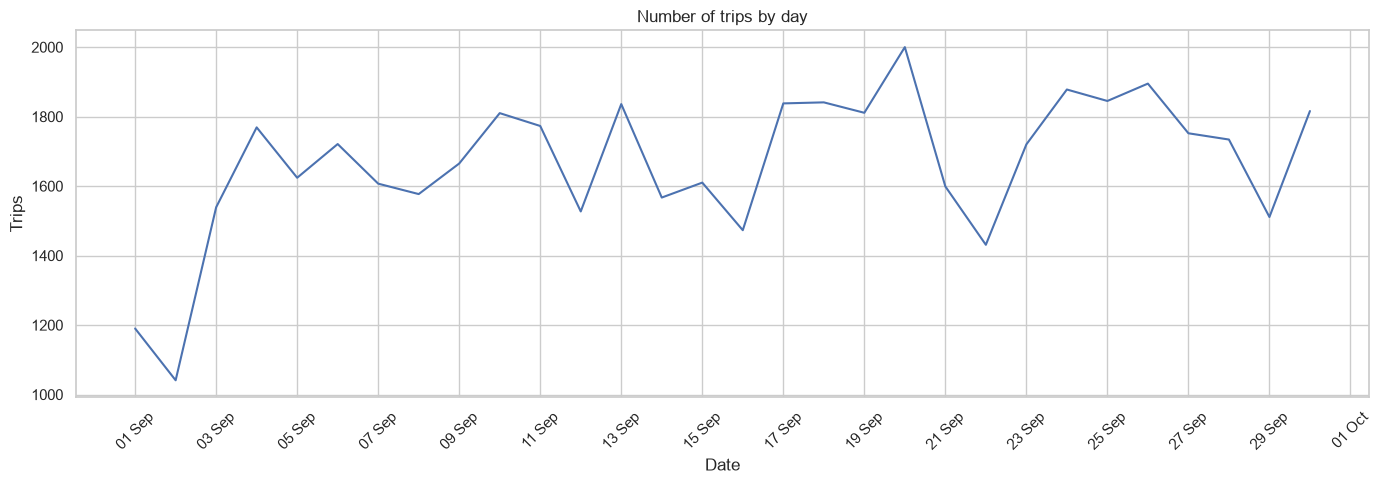

In [60]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    daily["date"],
    daily["trips"]
)

ax.set_title(
    "Number of trips by day"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Trips"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


 ## 7.2 Average duration

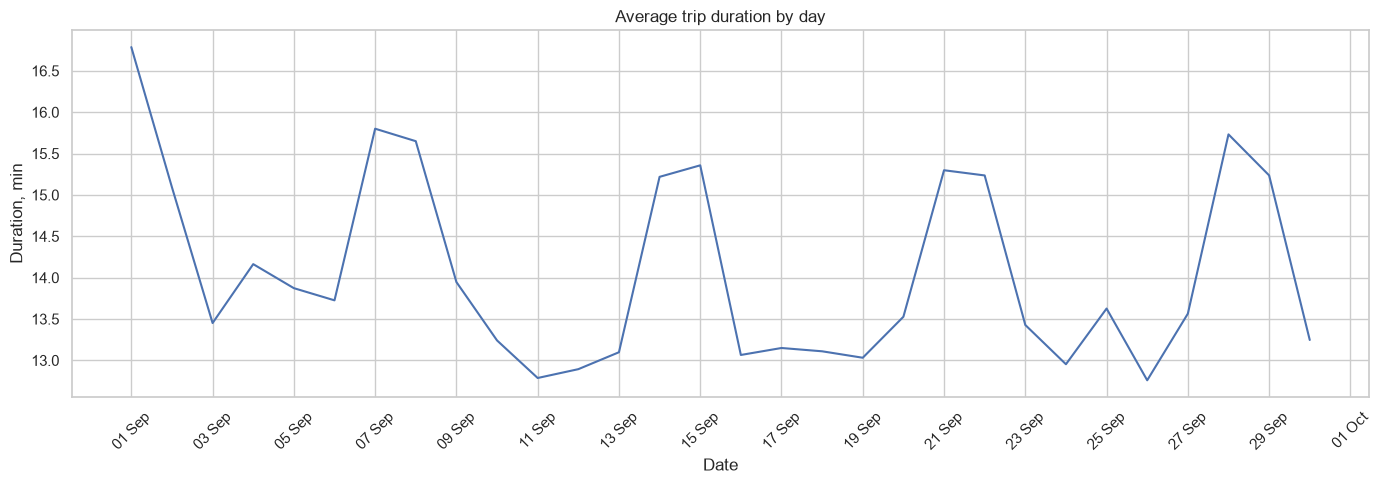

In [61]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    daily["date"],
    daily["avg_duration"]
)

ax.set_title(
    "Average trip duration by day"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Duration, min"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


 ## 7.3 Median duration

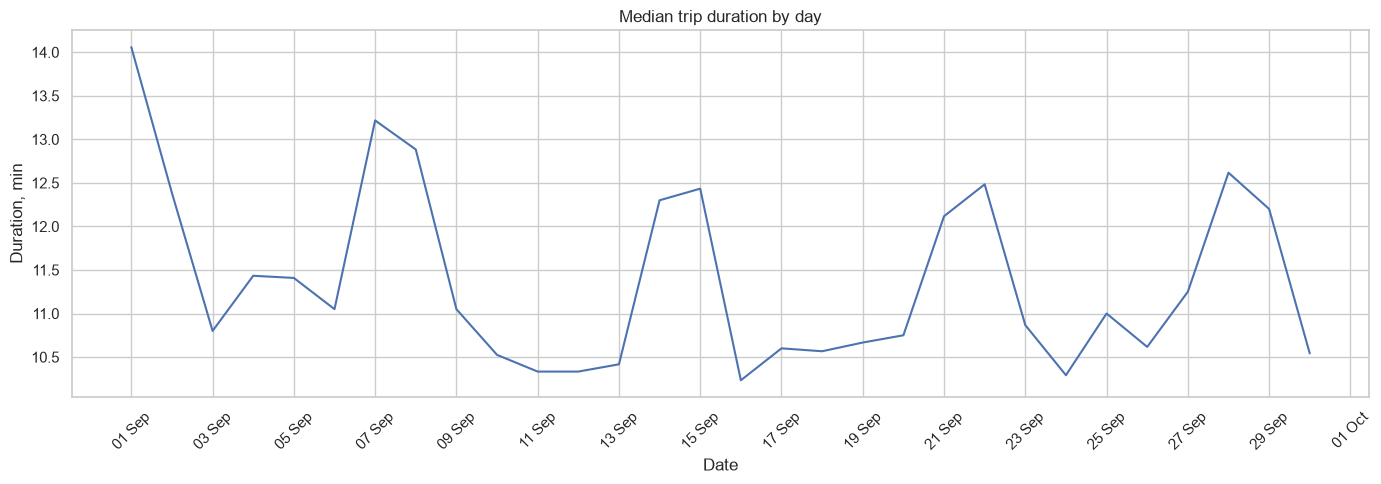

In [62]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    daily["date"],
    daily["median_duration"]
)

ax.set_title(
    "Median trip duration by day"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Duration, min"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


 ## 7.4 Average distance

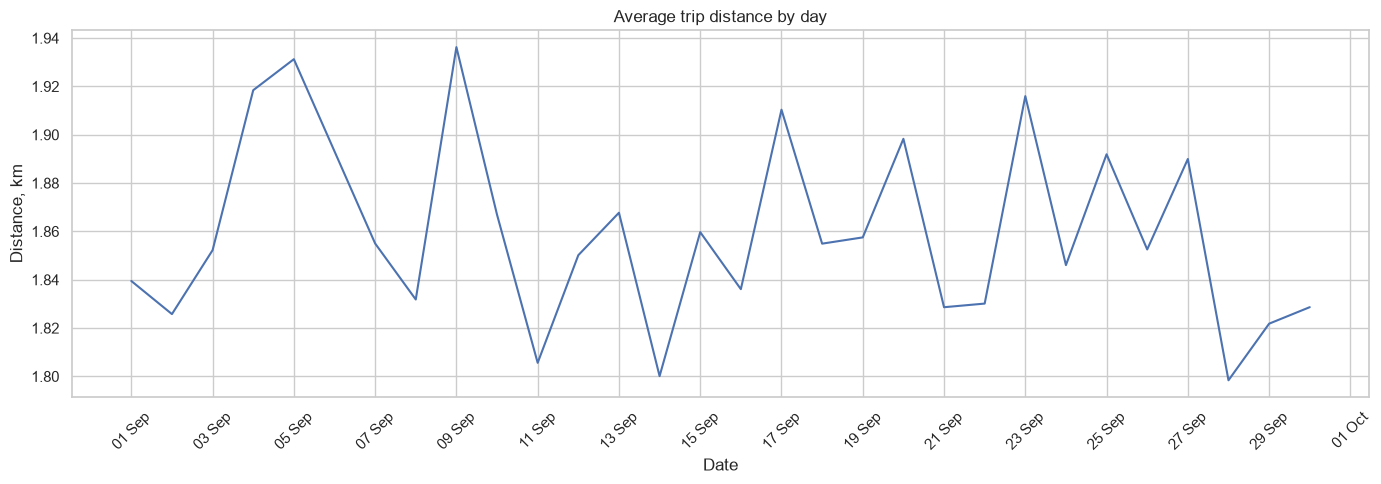

In [63]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    daily["date"],
    daily["avg_distance"]
)

ax.set_title(
    "Average trip distance by day"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Distance, km"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


 ## 7.5 Correlation check



 Проверяем, связаны ли дневной объём поездок, длительность и дистанция.

In [64]:
daily_correlation = (
    daily[
        [
            "trips",
            "avg_duration",
            "median_duration",
            "avg_distance"
        ]
    ]
    .corr()
)

display(
    daily_correlation.round(2)
)


,trips,avg_duration,median_duration,avg_distance
trips,1.00,-0.62,-0.63,0.35
avg_duration,-0.62,1.00,0.98,-0.35
median_duration,-0.63,0.98,1.00,-0.32
avg_distance,0.35,-0.35,-0.32,1.00


 ## H7 — Result



 Если период охватывает только один месяц:



 > В течение наблюдаемого периода объём поездок демонстрировал колебания

 > между днями. Эти изменения не обязательно сопровождались пропорциональными

 > изменениями продолжительности и дистанции.



 Сила связи между показателями определяется корреляционной матрицей выше.



 Корреляция не доказывает причинность.

 # 6. Final Summary

In [65]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total trips",
        "Unique trips",
        "Mean duration, min",
        "Median duration, min",
        "Mean distance, km",
        "Median distance, km",
        "Top-10 station appearances",
        "Top-10 share of station appearances, %"
    ],

    "Value": [
        len(df),
        df["trip_id"].nunique(),
        df["duration_min"].mean(),
        df["duration_min"].median(),
        df["distance_km"].mean(),
        df["distance_km"].median(),
        station_counts.head(10).sum(),
        station_counts.head(10).sum()
        / station_counts.sum()
        * 100
    ]
})

display(
    final_summary.round(2)
)


,Metric,Value
0,Total trips,50000.00
1,Unique trips,50000.00
2,"Mean duration, min",13.98
3,"Median duration, min",11.20
4,"Mean distance, km",1.86
5,"Median distance, km",1.49
6,Top-10 station appearances,8778.00
7,"Top-10 share of station appearances, %",8.78


 # 7. Conclusions



 ## What was analyzed



 - temporal demand;

 - trip duration;

 - route characteristics;

 - user segments;

 - Top-10 stations;

 - subscribers vs customers;

 - temporal dynamics.



 ## Analytical approach



 Проект использует последовательность:



 **Observation → Question → Hypothesis → Check → Result → Insight**



 Для проверки выводов использовались:



 - агрегирование;

 - сравнение групп;

 - mean и median;

 - доли;

 - сегментация;

 - анализ маршрутов;

 - дополнительные проверки;

 - correlation analysis.



 ## Limitations



 1. Если датасет охватывает только один месяц, нельзя делать сильные выводы

    о сезонности всего года.

 2. Корреляция не доказывает причинно-следственную связь.

 3. Среднее значение может быть чувствительно к выбросам, поэтому используется

    медиана.

 4. Для анализа маршрутов используется минимальный порог в 10 поездок.

 5. Расстояние между станциями рассчитывается по координатам и представляет

    географическое расстояние, а не фактический путь велосипеда по улицам.



 ## Next Steps



 - анализ нескольких месяцев или лет;

 - более глубокий анализ station imbalance;

 - анализ популярных маршрутов;

 - сравнение будних и выходных;

 - анализ пикового спроса;

 - создание Power BI dashboard.